In [3]:
import pandas as pd
import re

data = pd.DataFrame({
    'teks': [
        """Saya adalah perempuan yang cerdas, mandiri, dan memiliki semangat
        tinggi untuk meraih cita-cita. Saya percaya bahwa setiap tantangan
        merupakan kesempatan untuk belajar dan berkembang menjadi pribadi
        yang lebih baik. Saya dikenal sebagai seseorang yang bertanggung
        jawab, disiplin, dan mampu bekerja sama dengan orang lain. Selain
        berusaha meraih prestasi akademik, saya juga aktif dalam organisasi
        untuk mengembangkan kemampuan kepemimpinan, komunikasi, dan kerja
        sama tim. Saya bangga pada diri sendiri karena selalu berusaha
        memberikan yang terbaik, meskipun terkadang harus menghadapi
        berbagai kesulitan. Bagi saya, kesuksesan bukan hanya tentang
        pencapaian, tetapi juga tentang proses belajar, keberanian mencoba,
        dan konsistensi dalam memperbaiki diri. Saya yakin bahwa dengan
        ilmu, akhlak yang baik, doa, dan kerja keras, saya mampu mewujudkan
        impian serta menjadi perempuan berilmu yang bermanfaat bagi banyak orang."""
    ]
})

data.head()

,teks
0,"Saya adalah perempuan yang cerdas, mandiri, da..."


In [5]:
!pip install Sastrawi

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [6]:
import re

data['huruf_kecil'] = data['teks'].str.lower()
data['bersih'] = data['huruf_kecil'].str.replace(r'[^a-z0-9\s]', ' ', regex=True)
data['bersih'] = data['bersih'].str.replace(r'\s+', ' ', regex=True).str.strip()
data[['teks', 'bersih']].head()

,teks,bersih
0,"Saya adalah perempuan yang cerdas, mandiri, da...",saya adalah perempuan yang cerdas mandiri dan ...


In [8]:
contoh = data.loc[0, 'bersih']
token = contoh.split()
print('Teks:', contoh)
print('Token:', token)

Teks: saya adalah perempuan yang cerdas mandiri dan memiliki semangat tinggi untuk meraih cita cita saya percaya bahwa setiap tantangan merupakan kesempatan untuk belajar dan berkembang menjadi pribadi yang lebih baik saya dikenal sebagai seseorang yang bertanggung jawab disiplin dan mampu bekerja sama dengan orang lain selain berusaha meraih prestasi akademik saya juga aktif dalam organisasi untuk mengembangkan kemampuan kepemimpinan komunikasi dan kerja sama tim saya bangga pada diri sendiri karena selalu berusaha memberikan yang terbaik meskipun terkadang harus menghadapi berbagai kesulitan bagi saya kesuksesan bukan hanya tentang pencapaian tetapi juga tentang proses belajar keberanian mencoba dan konsistensi dalam memperbaiki diri saya yakin bahwa dengan ilmu akhlak yang baik doa dan kerja keras saya mampu mewujudkan impian serta menjadi perempuan berilmu yang bermanfaat bagi banyak orang
Token: ['saya', 'adalah', 'perempuan', 'yang', 'cerdas', 'mandiri', 'dan', 'memiliki', 'seman

In [9]:
!pip install Sastrawi

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)

['perempuan', 'cerdas', 'mandiri', 'memiliki', 'semangat', 'tinggi', 'meraih', 'cita', 'cita', 'percaya', 'tantangan', 'merupakan', 'kesempatan', 'belajar', 'berkembang', 'menjadi', 'pribadi', 'lebih', 'baik', 'dikenal', 'seseorang', 'bertanggung', 'jawab', 'disiplin', 'mampu', 'bekerja', 'sama', 'orang', 'berusaha', 'meraih', 'prestasi', 'akademik', 'aktif', 'organisasi', 'mengembangkan', 'kemampuan', 'kepemimpinan', 'komunikasi', 'kerja', 'sama', 'tim', 'bangga', 'diri', 'sendiri', 'selalu', 'berusaha', 'memberikan', 'terbaik', 'meskipun', 'terkadang', 'menghadapi', 'berbagai', 'kesulitan', 'kesuksesan', 'bukan', 'pencapaian', 'proses', 'belajar', 'keberanian', 'mencoba', 'konsistensi', 'memperbaiki', 'diri', 'yakin', 'ilmu', 'akhlak', 'baik', 'doa', 'kerja', 'keras', 'mampu', 'mewujudkan', 'impian', 'menjadi', 'perempuan', 'berilmu', 'bermanfaat', 'banyak', 'orang']


In [10]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['perempuan', 'cerdas', 'mandiri', 'memiliki', 'semangat', 'tinggi', 'meraih', 'cita', 'cita', 'percaya', 'tantangan', 'merupakan', 'kesempatan', 'belajar', 'berkembang', 'menjadi', 'pribadi', 'lebih', 'baik', 'dikenal', 'seseorang', 'bertanggung', 'jawab', 'disiplin', 'mampu', 'bekerja', 'sama', 'orang', 'berusaha', 'meraih', 'prestasi', 'akademik', 'aktif', 'organisasi', 'mengembangkan', 'kemampuan', 'kepemimpinan', 'komunikasi', 'kerja', 'sama', 'tim', 'bangga', 'diri', 'sendiri', 'selalu', 'berusaha', 'memberikan', 'terbaik', 'meskipun', 'terkadang', 'menghadapi', 'berbagai', 'kesulitan', 'kesuksesan', 'bukan', 'pencapaian', 'proses', 'belajar', 'keberanian', 'mencoba', 'konsistensi', 'memperbaiki', 'diri', 'yakin', 'ilmu', 'akhlak', 'baik', 'doa', 'kerja', 'keras', 'mampu', 'mewujudkan', 'impian', 'menjadi', 'perempuan', 'berilmu', 'bermanfaat', 'banyak', 'orang']
Sesudah: ['perempuan', 'cerdas', 'mandiri', 'milik', 'semangat', 'tinggi', 'raih', 'cita', 'cita', 'percaya',

In [11]:
from collections import Counter
import matplotlib.pyplot as plt

semua_kata = ' '.join(data['bersih']).split()
frekuensi = Counter(
    kata for kata in semua_kata if kata not in stopwords
)
print(frekuensi.most_common(10))

[('perempuan', 2), ('meraih', 2), ('cita', 2), ('belajar', 2), ('menjadi', 2), ('baik', 2), ('mampu', 2), ('sama', 2), ('orang', 2), ('berusaha', 2)]


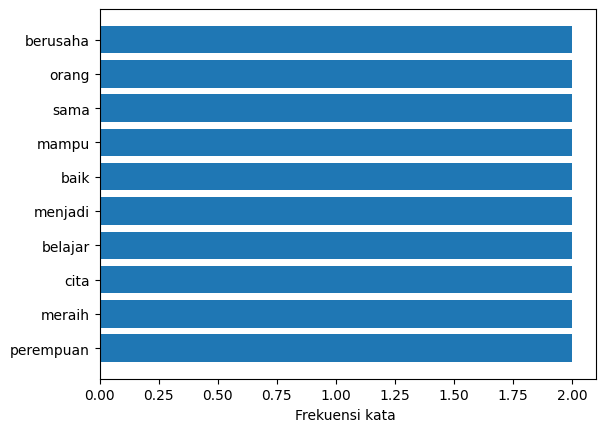

In [12]:
kata , jumlah = zip (* frekuensi . most_common (10) )
plt . barh ( kata , jumlah )
plt . xlabel ('Frekuensi kata ')
plt . show ()

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih'].head(5)
count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

,adalah,akademik,akhlak,aktif,bagi,bahwa,baik,bangga,banyak,bekerja,...,tantangan,tentang,terbaik,terkadang,tetapi,tim,tinggi,untuk,yakin,yang
0,1,1,1,1,2,2,2,1,1,1,...,1,2,1,1,1,1,1,3,1,6


In [14]:
from sklearn . feature_extraction . text import TfidfVectorizer
tfidf = TfidfVectorizer ()
matriks_tfidf = tfidf . fit_transform ( dokumen )
pd . DataFrame (
matriks_tfidf . toarray () ,
columns = tfidf . get_feature_names_out ()
) . round (2)

,adalah,akademik,akhlak,aktif,bagi,bahwa,baik,bangga,banyak,bekerja,...,tantangan,tentang,terbaik,terkadang,tetapi,tim,tinggi,untuk,yakin,yang
0,0.06,0.06,0.06,0.06,0.12,0.12,0.12,0.06,0.06,0.06,...,0.06,0.12,0.06,0.06,0.06,0.06,0.06,0.18,0.06,0.36


data dari google

In [15]:

!pip install -q datasets

import pandas as pd
from datasets import load_dataset

# Memanggil dataset dari Hugging Face
dataset = load_dataset(
    "AIbnuHibban/e-commerce-sentiment-bahasa-indonesia"
)

# Mengubah dataset menjadi DataFrame
data = dataset["train"].to_pandas()

# Menyesuaikan nama kolom
data = data.rename(
    columns={
        "comment": "teks",
        "sentiment": "label_asli"
    }
)

# Mengambil kolom yang diperlukan
data = data[["teks", "label_asli"]].dropna()

# Menampilkan data
print("Jumlah data:", len(data))
display(data.head())


README.md:   0%|          | 0.00/2.31k [00:00<?, ?B/s]

challange.json:   0%|          | 0.00/634k [00:00<?, ?B/s]

simple.json:   0%|          | 0.00/1.86M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/21840 [00:00<?, ? examples/s]

Jumlah data: 21840


,teks,label_asli
0,Wah mantap banget nih ditipu! Terima kasih sel...,negative
1,"Bagus sekali, barang rusak semua! Top markotop!",negative
2,Pelayanan terbaik! Nungguin 2 minggu cuma buat...,negative
3,Seneng banget barangnya cacat. Recommended sel...,negative
4,Keren nih seller! Kirim barang yang salah deng...,negative


In [16]:
print("Nama kolom:", data.columns.tolist())

print("\nJumlah setiap label sentimen:")
print(data["label_asli"].value_counts())

print("\nContoh teks ulasan:")
print(data["teks"].iloc[0])


Nama kolom: ['teks', 'label_asli']

Jumlah setiap label sentimen:
label_asli
positive    7480
negative    7470
neutral     6890
Name: count, dtype: int64

Contoh teks ulasan:
Wah mantap banget nih ditipu! Terima kasih seller 😊


In [18]:
print('Ukuran data:', data.shape)
print('Nilai kosong:')
print(data.isna().sum())
print('Jumlah label:')
print(data['label_asli'].value_counts())

Ukuran data: (21840, 2)
Nilai kosong:
teks          0
label_asli    0
dtype: int64
Jumlah label:
label_asli
positive    7480
negative    7470
neutral     6890
Name: count, dtype: int64


In [19]:
import re

data['huruf_kecil'] = data['teks'].str.lower()
data['bersih'] = data['huruf_kecil'].str.replace(r'[^a-z0-9\s]', ' ', regex=True)
data['bersih'] = data['bersih'].str.replace(r'\s+', ' ', regex=True).str.strip()
data[['teks', 'bersih']].head()

,teks,bersih
0,Wah mantap banget nih ditipu! Terima kasih sel...,wah mantap banget nih ditipu terima kasih seller
1,"Bagus sekali, barang rusak semua! Top markotop!",bagus sekali barang rusak semua top markotop
2,Pelayanan terbaik! Nungguin 2 minggu cuma buat...,pelayanan terbaik nungguin 2 minggu cuma buat ...
3,Seneng banget barangnya cacat. Recommended sel...,seneng banget barangnya cacat recommended seller
4,Keren nih seller! Kirim barang yang salah deng...,keren nih seller kirim barang yang salah denga...


In [27]:
contoh = data.loc[2, 'bersih']
token = contoh.split()
print('Teks:', contoh)
print('Token:', token)

Teks: pelayanan terbaik nungguin 2 minggu cuma buat barang ga dateng
Token: ['pelayanan', 'terbaik', 'nungguin', '2', 'minggu', 'cuma', 'buat', 'barang', 'ga', 'dateng']


In [28]:
!pip install Sastrawi

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)

['pelayanan', 'terbaik', 'nungguin', '2', 'minggu', 'cuma', 'buat', 'barang', 'ga', 'dateng']


In [29]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['pelayanan', 'terbaik', 'nungguin', '2', 'minggu', 'cuma', 'buat', 'barang', 'ga', 'dateng']
Sesudah: ['layan', 'baik', 'nungguin', '2', 'minggu', 'cuma', 'buat', 'barang', 'ga', 'dateng']


In [30]:
from collections import Counter
import matplotlib.pyplot as plt

semua_kata = ' '.join(data['bersih']).split()
frekuensi = Counter(
    kata for kata in semua_kata if kata not in stopwords
)
print(frekuensi.most_common(10))

[('banget', 3075), ('tidak', 2315), ('ga', 2154), ('produk', 2041), ('bagus', 1930), ('sesuai', 1856), ('oke', 1739), ('barang', 1652), ('sih', 1624), ('aja', 1623)]


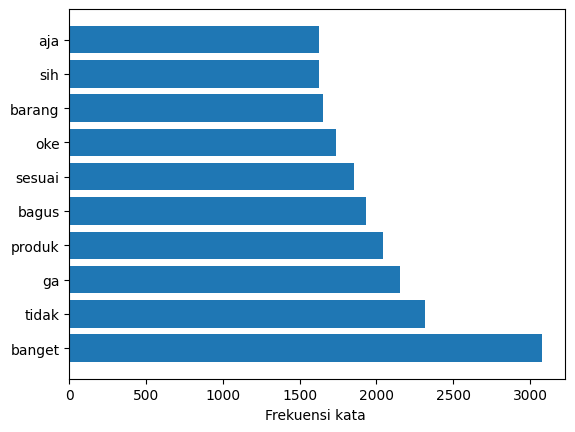

In [31]:
kata , jumlah = zip (* frekuensi . most_common (10) )
plt . barh ( kata , jumlah )
plt . xlabel ('Frekuensi kata ')
plt . show ()

In [32]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih'].head(5)
count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

,bagus,banget,barang,barangnya,buat,cacat,cuma,dateng,dengan,diri,...,salah,sekali,seller,semua,seneng,terbaik,terima,top,wah,yang
0,0,1,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,1,0
1,1,0,1,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,1,0,0
2,0,0,1,0,1,0,1,1,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,1,0,1,0,1,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
4,0,0,1,0,0,0,0,0,1,1,...,1,0,1,0,0,0,0,0,0,1


In [33]:
from sklearn . feature_extraction . text import TfidfVectorizer
tfidf = TfidfVectorizer ()
matriks_tfidf = tfidf . fit_transform ( dokumen )
pd . DataFrame (
matriks_tfidf . toarray () ,
columns = tfidf . get_feature_names_out ()
) . round (2)

,bagus,banget,barang,barangnya,buat,cacat,cuma,dateng,dengan,diri,...,salah,sekali,seller,semua,seneng,terbaik,terima,top,wah,yang
0,0.00,0.31,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.26,0.00,0.00,0.00,0.38,0.00,0.38,0.00
1,0.39,0.00,0.26,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.39,0.00,0.39,0.00,0.00,0.00,0.39,0.00,0.00
2,0.00,0.00,0.23,0.00,0.34,0.00,0.34,0.34,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.34,0.00,0.00,0.00,0.00
3,0.00,0.36,0.00,0.44,0.00,0.44,0.00,0.00,0.00,0.00,...,0.00,0.00,0.30,0.00,0.44,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.23,0.00,0.00,0.00,0.00,0.00,0.34,0.34,...,0.34,0.00,0.23,0.00,0.00,0.00,0.00,0.00,0.00,0.34
